# Lab assignment №1, part 3

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the third part of the assignment. First and second parts are waiting for you in the same directory.*__

##  Part 3. SVM and kernels

Kernels concept get adopted in variety of ML algorithms (e.g. Kernel PCA, Gaussian Processes, kNN, ...).

So in this task you are to examine kernels for SVM algorithm applied to rather simple artificial datasets.

To make it clear: we will work with the classification problem through the whole notebook. 

In [1]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('error', category=ConvergenceWarning)
SEED = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
plt.rcParams.update({'figure.figsize': (6, 5), 'axes.grid': True})

# Предсказываем по сетке исходных координат; Pipeline сам преобразует признаки.
def plot_decisions(points, labels, model, title, ax):
    x0 = np.linspace(points[:, 0].min() - 0.4, points[:, 0].max() + 0.4, 250)
    x1 = np.linspace(points[:, 1].min() - 0.4, points[:, 1].max() + 0.4, 250)
    xx, yy = np.meshgrid(x0, x1)
    # Превращаем координатную сетку в список точек (x1, x2).
    grid_x = xx.flatten()
    grid_y = yy.flatten()
    grid_points = np.column_stack((grid_x, grid_y))

    # Предсказываем класс каждой точки и возвращаем форму сетки для рисунка.
    predictions = model.predict(grid_points)
    predictions = predictions.reshape(xx.shape)
    levels = np.arange(len(np.unique(labels)) + 1) - 0.5
    from matplotlib.colors import ListedColormap
    palette = ListedColormap(plt.get_cmap('tab10').colors[:len(np.unique(labels))])
    ax.contourf(xx, yy, predictions, levels=levels, cmap=palette, alpha=0.25)
    ax.scatter(points[:, 0], points[:, 1], c=labels, cmap=palette,
               vmin=-0.5, vmax=len(np.unique(labels))-0.5,
               s=14, edgecolors='black', linewidths=0.3)
    ax.set(xlabel='x1', ylabel='x2', title=title)


Let's generate our dataset and take a look on it.

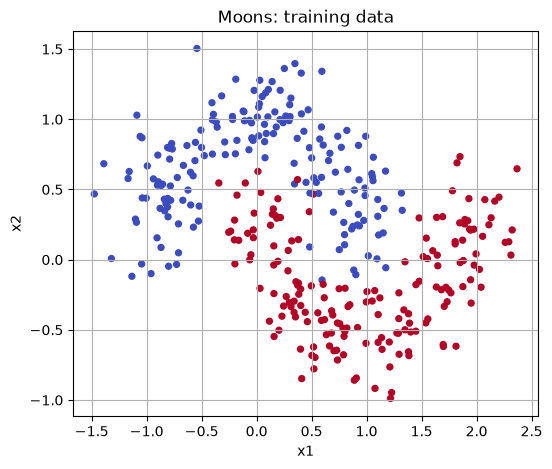

In [2]:
moons_points, moons_labels = make_moons(n_samples=500, noise=0.2, random_state=SEED)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    moons_points, moons_labels, test_size=0.3, stratify=moons_labels, random_state=SEED
)
plt.scatter(Xm_train[:, 0], Xm_train[:, 1], c=ym_train, cmap='coolwarm', s=18)
plt.title('Moons: training data')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()


## 1.1 Pure models.
First let's try to solve this case with good old Logistic Regression and simple (linear kernel) SVM classifier.

Train LR and SVM classifiers (choose params by hand, no CV or intensive grid search neeeded) and plot their decision regions. Calculate one preffered classification metric.

Describe results in one-two sentences.

_Tip:_ to plot classifiers decisions you colud use either sklearn examples ([this](https://scikit-learn.org/stable/auto_examples/neural_networks/plot_mlp_alpha.html#sphx-glr-auto-examples-neural-networks-plot-mlp-alpha-py) or any other) and mess with matplotlib yourself or great [mlxtend](https://github.com/rasbt/mlxtend) package (see their examples for details)

_Pro Tip:_ wirte function `plot_decisions` taking a dataset and an estimator and plotting the results cause you want to use it several times below

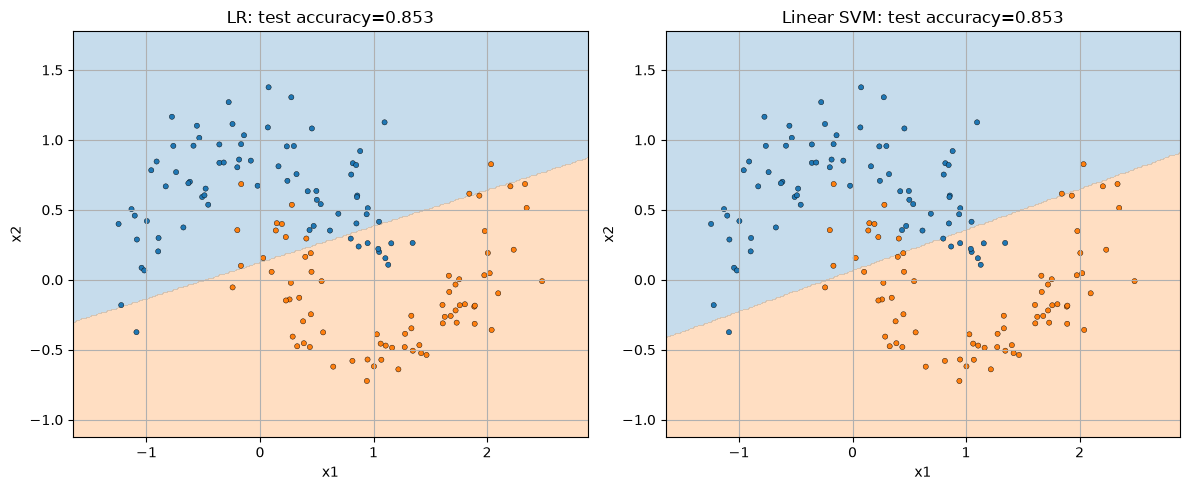

,model,test_accuracy
0,LR,0.853333
1,Linear SVM,0.853333


In [3]:
# Параметры базовых линейных моделей заданы вручную, как просит условие.
lr = Pipeline([('scale', StandardScaler()),
               ('model', LogisticRegression(C=1, max_iter=2000, random_state=SEED))])
svm = Pipeline([('scale', StandardScaler()), ('model', SVC(kernel='linear', C=1))])
moon_results = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
models = {'LR': lr, 'Linear SVM': svm}
for plot_index, name in enumerate(models):
    model = models[name]
    ax = axes[plot_index]
    model.fit(Xm_train, ym_train)
    score = accuracy_score(ym_test, model.predict(Xm_test))
    moon_results.append({'model': name, 'test_accuracy': score})
    plot_decisions(Xm_test, ym_test, model, f'{name}: test accuracy={score:.3f}', ax)
plt.tight_layout()
plt.show()
display(pd.DataFrame(moon_results))


**Линейные модели.** Классы moons имеют изогнутую форму, которую одна прямая
не описывает. LR и линейная SVM отличаются функцией потерь, но обе дают линейную
границу в исходных координатах. Accuracy считаем на отдельных 150 test-точках;
на рисунках показаны эти точки поверх областей решений.

Выполненный эксперимент: accuracy обеих моделей — 0,8533. На рисунках видны почти совпадающие прямые границы и ошибки возле изгибов moons.


## 1.2 Kernel tirck

Now use different kernels (`poly`, `rbf`, `sigmoid`) on SVC to get better results. Play `degree` parameter and others.

For each kernel estimate optimal params, plot decision regions, calculate metric you've chosen eariler.

Write couple of sentences on:

* What have happenned with classification quality?
* How did decision border changed for each kernel?
* What `degree` have you chosen and why?

poly {'model__C': 10, 'model__coef0': 1, 'model__degree': 5, 'model__gamma': 'scale'} CV accuracy: 0.9828571428571429
rbf {'model__C': 10, 'model__gamma': 1} CV accuracy: 0.9800000000000001


sigmoid {'model__C': 10, 'model__coef0': -1, 'model__gamma': 0.1} CV accuracy: 0.8714285714285716


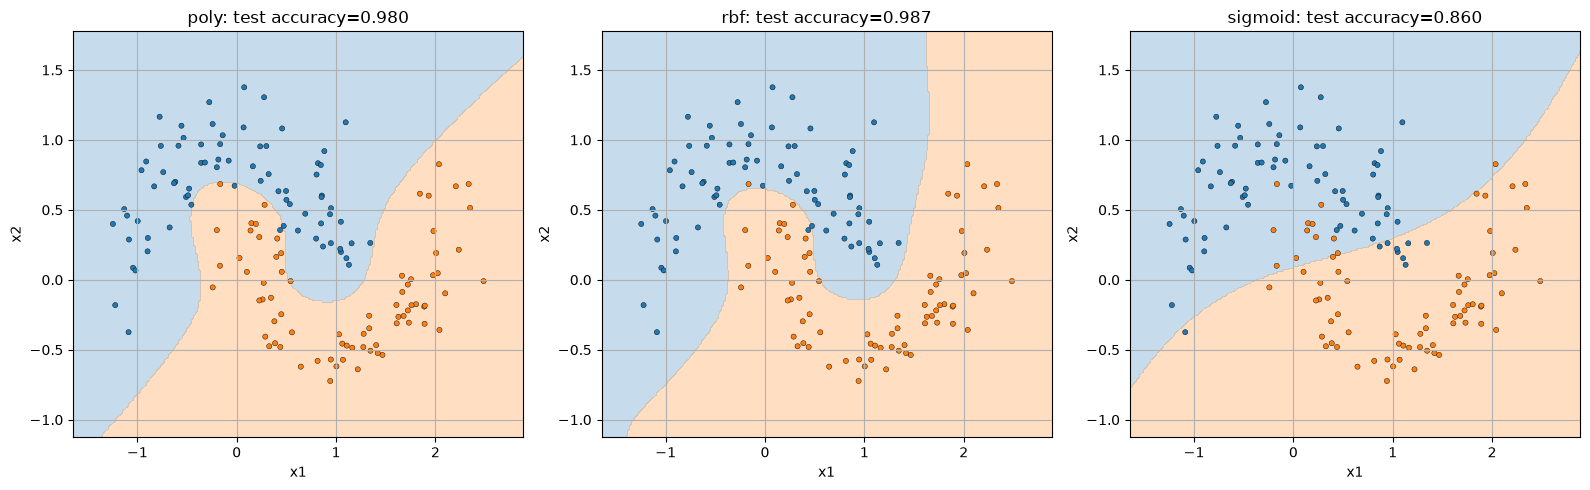

,model,test_accuracy,cv_accuracy
0,LR,0.8533,NaN
1,Linear SVM,0.8533,NaN
2,SVM poly,0.9800,0.9829
3,SVM rbf,0.9867,0.9800
4,SVM sigmoid,0.8600,0.8714


In [4]:
# Небольшой поиск только на train. Test не используется для выбора параметров.
kernel_grids = {
    'poly': {'model__C': [0.1, 1, 10], 'model__degree': [2, 3, 4, 5],
             'model__gamma': ['scale'], 'model__coef0': [0, 1]},
    'rbf': {'model__C': [0.1, 1, 10], 'model__gamma': [0.1, 0.5, 1, 2]},
    'sigmoid': {'model__C': [0.1, 1, 10], 'model__gamma': [0.01, 0.1, 1],
                'model__coef0': [-1, 0, 1]}
}
kernel_searches = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for plot_index, kernel in enumerate(kernel_grids):
    grid = kernel_grids[kernel]
    ax = axes[plot_index]
    pipeline = Pipeline([('scale', StandardScaler()),
                         ('model', SVC(kernel=kernel))])
    search = GridSearchCV(pipeline, grid, scoring='accuracy', cv=cv, n_jobs=1, error_score='raise')
    search.fit(Xm_train, ym_train)
    kernel_searches[kernel] = search
    score = accuracy_score(ym_test, search.predict(Xm_test))
    moon_results.append({'model': f'SVM {kernel}', 'test_accuracy': score,
                         'cv_accuracy': search.best_score_})
    print(kernel, search.best_params_, 'CV accuracy:', search.best_score_)
    plot_decisions(Xm_test, ym_test, search.best_estimator_,
                   f'{kernel}: test accuracy={score:.3f}', ax)
plt.tight_layout()
plt.show()
display(pd.DataFrame(moon_results).round(4))


**Ядра.** RBF даёт локальную гибкую границу, poly — полиномиальную,
sigmoid не гарантирует улучшения: его форма и доступная сетка параметров могут
не соответствовать данным. Для sigmoid не всякая комбинация параметров задаёт
положительно полуопределённое ядро; SVC принимает эти параметры, но обычные
гарантии выпуклой задачи SVM тогда не универсальны.

Степень poly выбираем по пятифолдовой train-CV, а не по внешнему виду test-графика.
Большая degree увеличивает гибкость, но не гарантирует лучшей accuracy.
Окончательные degree, C, gamma и coef0 напечатаны выше вместе с CV-оценкой.
Фактические различия качества приведены в итоговых таблицах.

**Результат запуска.** Poly: degree=5, C=10, coef0=1, gamma=scale; CV accuracy=0,9829, test=0,9800. RBF: C=10, gamma=1; CV=0,9800, test=0,9867. Sigmoid: C=10, gamma=0,1, coef0=−1; CV=0,8714, test=0,8600. Poly и RBF изгибаются вдоль moons и заметно лучше линейной SVM; sigmoid даёт лишь небольшое улучшение, его граница остаётся близкой к прямой. Степень 5 выбрана максимумом CV на сетке 2–5; глобальный оптимум степени не утверждается.


## 1.3 Simpler solution (of a kind)
What is we could use Logisitc Regression to successfully solve this task?

Feature generation is a thing to help here. Different techniques of feature generation are used in real life, couple of them will be covered in additional lectures.

In particular case simple `PolynomialFeatures` ([link](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)) are able to save the day.

Generate the set of new features, train LR on it, plot decision regions, calculate metric.

* Comare SVM's results with this solution (quality, borders type)
* What degree of PolynomialFeatures have you used? Compare with same SVM kernel parameter.

Polynomial LR: {'model__C': 10, 'poly__degree': 5} CV: 0.9685714285714286


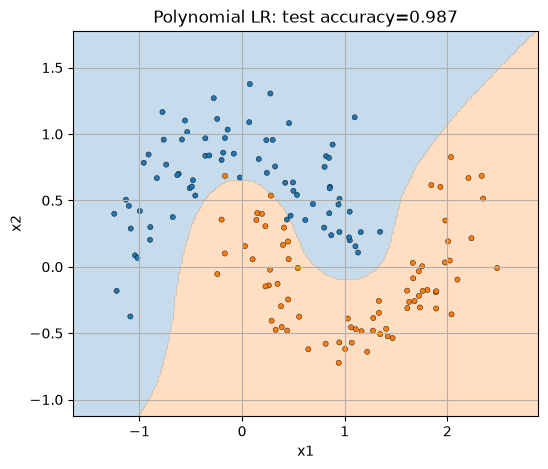

,test_accuracy,cv_accuracy
model,,
LR,0.8533,NaN
Linear SVM,0.8533,NaN
SVM poly,0.9800,0.9829
SVM rbf,0.9867,0.9800
SVM sigmoid,0.8600,0.8714
Polynomial LR,0.9867,0.9686


In [5]:
poly_lr = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=5000, random_state=SEED))
])
poly_lr_search = GridSearchCV(
    poly_lr, {'poly__degree': [2, 3, 4, 5], 'model__C': [0.1, 1, 10]},
    scoring='accuracy', cv=cv, n_jobs=1, error_score='raise'
)
poly_lr_search.fit(Xm_train, ym_train)
poly_lr_score = accuracy_score(ym_test, poly_lr_search.predict(Xm_test))
moon_results.append({'model': 'Polynomial LR', 'test_accuracy': poly_lr_score,
                     'cv_accuracy': poly_lr_search.best_score_})
print('Polynomial LR:', poly_lr_search.best_params_, 'CV:', poly_lr_search.best_score_)
fig, ax = plt.subplots()
plot_decisions(Xm_test, ym_test, poly_lr_search.best_estimator_,
               f'Polynomial LR: test accuracy={poly_lr_score:.3f}', ax)
plt.show()
moon_table = pd.DataFrame(moon_results).set_index('model')
display(moon_table.round(4))


**Явные признаки.** PolynomialFeatures создаёт степени и произведения
координат, например при degree=2: $x_1,x_2,x_1^2,x_1x_2,x_2^2$.
Линейная LR в этих признаках имеет полиномиальную границу в исходной плоскости.
Степень выбирается той же train-CV; её значение приведено в выводе.

У полиномиальной SVM параметр degree связан с
$K(x,z)=(\gamma x^Tz+\mathrm{coef0})^d$. При coef0=0 это однородные
признаки степени d, а PolynomialFeatures включает все степени до d.
При ненулевом coef0 ядро включает и младшие степени, но с другими весами.
Даже одинаковые degree не означают одну модель: различаются масштабирование,
геометрия регуляризации и логистическая/hinge-функция потерь.
RBF не ограничивается конечной полиномиальной степенью.

**Результат запуска.** У LR выбраны degree=5 и C=10, CV accuracy=0,9686, test=0,9867. Это тот же test-результат, что у RBF-SVM, и немного выше poly-SVM (0,9800). Степень совпала с poly-SVM (5), но контуры различаются: одинаковая степень не задаёт одинаковый классификатор.


## 1.4 Harder problem

Let's make this task a bit more challenging via upgrading dataset:

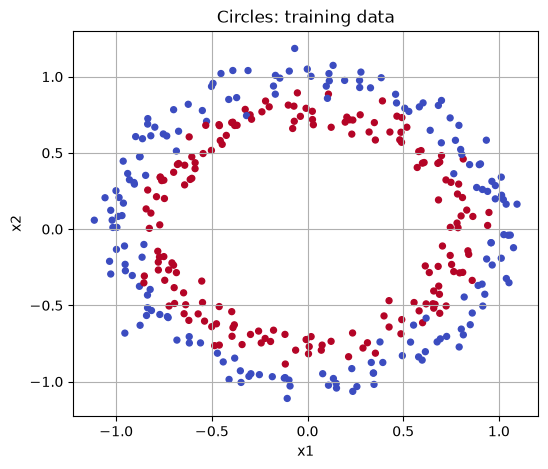

In [6]:
from sklearn.datasets import make_circles

circles_points, circles_labels = make_circles(n_samples=500, noise=0.06, random_state=SEED)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    circles_points, circles_labels, test_size=0.3, stratify=circles_labels, random_state=SEED
)
plt.scatter(Xc_train[:, 0], Xc_train[:, 1], c=yc_train, cmap='coolwarm', s=18)
plt.title('Circles: training data')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()


And even more:

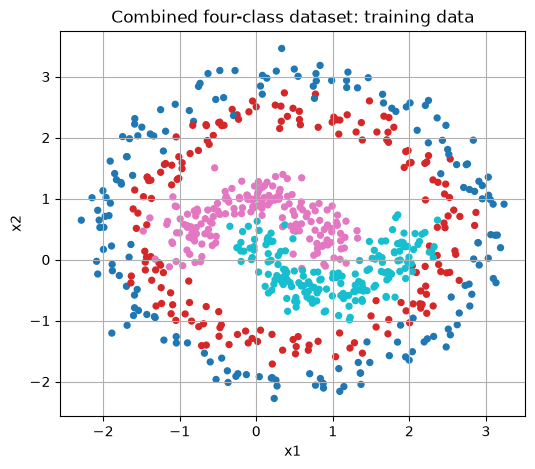

In [7]:
points = np.vstack((circles_points * 2.5 + 0.5, moons_points))
labels = np.hstack((circles_labels, moons_labels + 2))
# Используем те же части circles и moons: уже просмотренные test-точки moons
# не становятся обучающими точками нового составного эксперимента.
Xh_train = np.vstack((Xc_train * 2.5 + 0.5, Xm_train))
Xh_test = np.vstack((Xc_test * 2.5 + 0.5, Xm_test))
yh_train = np.hstack((yc_train, ym_train + 2))
yh_test = np.hstack((yc_test, ym_test + 2))
plt.scatter(Xh_train[:, 0], Xh_train[:, 1], c=yh_train, cmap='tab10', s=18)
plt.title('Combined four-class dataset: training data')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()


Now do your best using all the approaches above!

Tune LR with generated features, SVM with appropriate kernel of your choice. You may add some of your loved models to demonstrate their (and your) strength. Again plot decision regions, calculate metric.

Justify the results in a few phrases.

Circles LR {'model__C': 0.1}
Circles Linear SVM {'model__C': 0.1}


Circles Polynomial LR {'model__C': 0.1, 'poly__degree': 2}


Circles SVM poly {'model__C': 0.1, 'model__coef0': 1, 'model__degree': 5, 'model__gamma': 'scale'}


Circles SVM rbf {'model__C': 10, 'model__gamma': 0.1}


Circles SVM sigmoid {'model__C': 10, 'model__coef0': -1, 'model__gamma': 0.1}


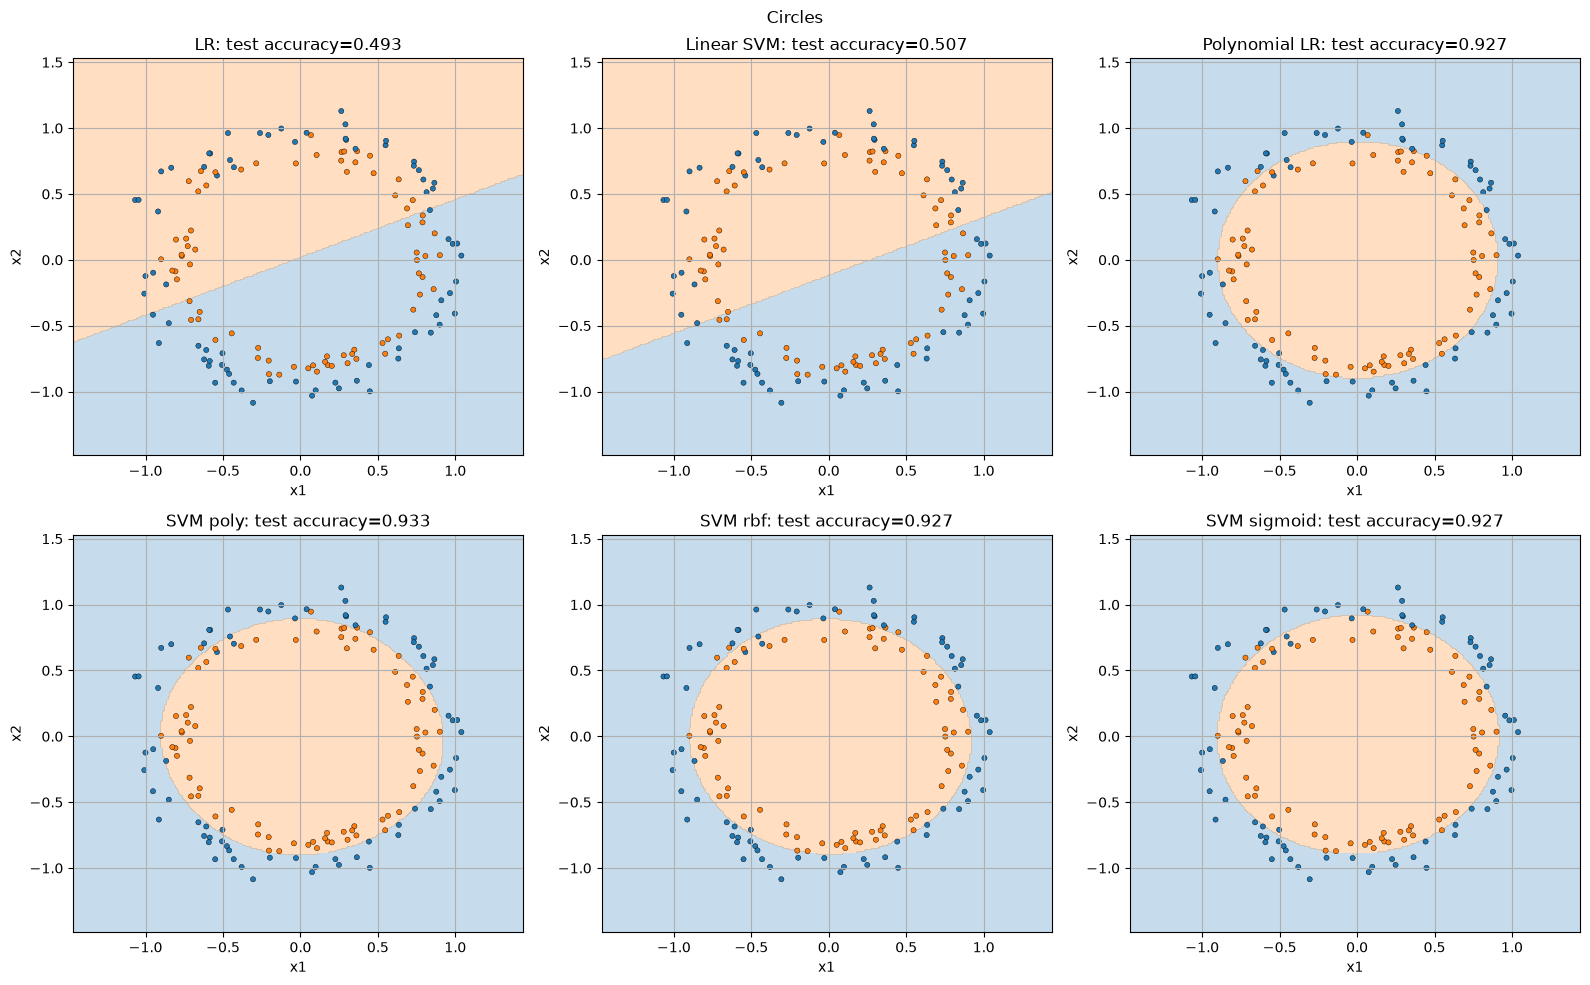

Combined LR {'model__C': 0.1}
Combined Linear SVM {'model__C': 10}


Combined Polynomial LR {'model__C': 10, 'poly__degree': 4}


Combined SVM poly {'model__C': 10, 'model__coef0': 1, 'model__degree': 5, 'model__gamma': 'scale'}


Combined SVM rbf {'model__C': 10, 'model__gamma': 1}


Combined SVM sigmoid {'model__C': 10, 'model__coef0': -1, 'model__gamma': 0.1}


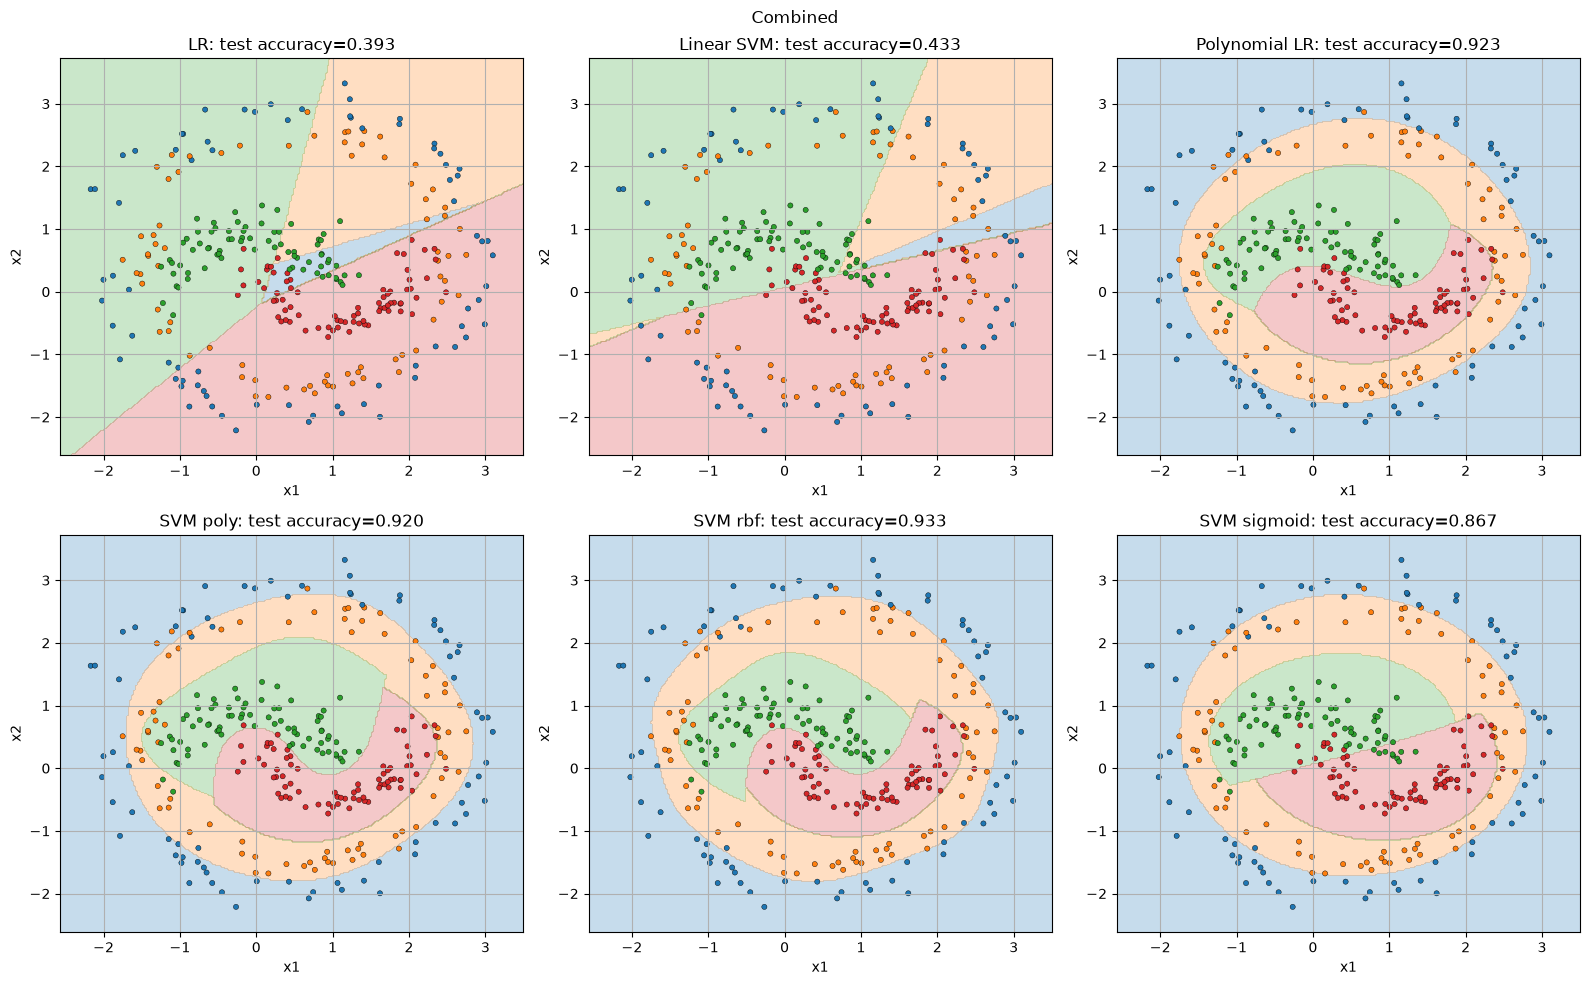

,dataset,model,cv_accuracy,test_accuracy
0,Circles,LR,0.4771,0.4933
1,Circles,Linear SVM,0.4771,0.5067
2,Circles,Polynomial LR,0.9457,0.9267
3,Circles,SVM poly,0.9486,0.9333
4,Circles,SVM rbf,0.9514,0.9267
5,Circles,SVM sigmoid,0.9429,0.9267
6,Combined,LR,0.4029,0.3933
7,Combined,Linear SVM,0.4500,0.4333
8,Combined,Polynomial LR,0.9186,0.9233
9,Combined,SVM poly,0.9329,0.9200


In [8]:
from sklearn.base import clone

# Сравниваем все подходы на кругах и на составной четырёхклассовой задаче.
hard_results = []
hard_searches = {}
datasets = {
    'Circles': (Xc_train, Xc_test, yc_train, yc_test),
    'Combined': (Xh_train, Xh_test, yh_train, yh_test)
}
for dataset_name in datasets:
    Xtr, Xte, ytr, yte = datasets[dataset_name]
    # Отдельно перечисляем модели и параметры, которые будем перебирать.
    models = {
        'LR': clone(lr),
        'Linear SVM': clone(svm),
        'Polynomial LR': clone(poly_lr)
    }
    parameter_grids = {
        'LR': {'model__C': [0.1, 1, 10]},
        'Linear SVM': {'model__C': [0.1, 1, 10]},
        'Polynomial LR': {
            'poly__degree': [2, 3, 4, 5, 6],
            'model__C': [0.1, 1, 10]
        }
    }
    for kernel in kernel_grids:
        name = f'SVM {kernel}'
        models[name] = Pipeline([
            ('scale', StandardScaler()),
            ('model', SVC(kernel=kernel))
        ])
        parameter_grids[name] = kernel_grids[kernel]
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    plot_axes = axes.flatten()
    for plot_index, name in enumerate(models):
        pipeline = models[name]
        grid = parameter_grids[name]
        ax = plot_axes[plot_index]
        search = GridSearchCV(pipeline, grid, scoring='accuracy', cv=cv, n_jobs=1, error_score='raise')
        search.fit(Xtr, ytr)
        hard_searches[(dataset_name, name)] = search
        score = accuracy_score(yte, search.predict(Xte))
        hard_results.append({'dataset': dataset_name, 'model': name,
                             'cv_accuracy': search.best_score_, 'test_accuracy': score})
        print(dataset_name, name, search.best_params_)
        plot_decisions(Xte, yte, search.best_estimator_,
                       f'{name}: test accuracy={score:.3f}', ax)
    fig.suptitle(dataset_name)
    plt.tight_layout()
    plt.show()
hard_table = pd.DataFrame(hard_results)
display(hard_table.round(4))


**Более сложные данные.** Круги нельзя разделить прямой: классы
различаются радиусом, и уже $x_1^2+x_2^2$ даёт полезный признак.
На составной задаче нужно одновременно описать кольца и moons, а четыре класса
частично перекрываются. Поэтому хорошее качество на отдельных moons не означает
такого же качества на объединении. SVC обучает многоклассовую модель через пары
классов, LR — через вероятности классов; accuracy по-прежнему измеряет долю верных
меток. Все параметры выбраны только на train, таблицы показывают CV и test отдельно.

Графики — срез классификатора, а не доказательство качества вне области данных.
Один test-split и небольшая сетка не дают статистически надёжного рейтинга моделей;
результаты относятся к указанным генераторам, шуму и seed.

**Результат запуска.** На circles линейные модели дают около 0,5 accuracy, тогда как LR с degree=2 — 0,9267, poly-SVM — 0,9333, RBF и sigmoid — 0,9267. Квадратичных признаков LR хватает для кольцевой границы. Степень poly-SVM по CV равна 5: разница с LR показывает роль функции потерь, регуляризации и параметризации; небольшое преимущество test не доказывает необходимость пятой степени.

На объединённой задаче LR=0,3933 и линейная SVM=0,4333; полиномиальная LR (degree=4)=0,9233, poly-SVM (degree=5)=0,9200, RBF=0,9333, sigmoid=0,8667. Нелинейные модели одновременно выделяют кольца и изгибы moons. У sigmoid на составной задаче появляются неверно размеченные периферийные области, что согласуется с меньшей accuracy. Параметры после просмотра этих test-результатов не менялись.
